# K-means CPU baseline: the reference point for the GPU comparison

This notebook measures **K-means (Lloyd's algorithm) on the CPU** for every synthetic dataset and records the numbers the GPU run is compared against.
It runs on a **Google Colab CPU runtime** or on a local machine without changes.

**What it produces** (in `OUT_DIR`):

| File | Contents |
| --- | --- |
| `summary.csv` | One row per dataset: time per iteration (median of 5 timed runs), iterations to converge, total time, cluster sizes. **This is the baseline table.** |
| `environment.json` | CPU model, cores, threads used, RAM, library versions and settings. |
| `initial_centroids_<file>.csv` | k-means++ starting centroids for each dataset. **The GPU run must load these.** |
| `final_results_<file>.csv` | Execution time, iterations, max movement and final centroids for the run to convergence. |
| `assignments/assignments_<file>.csv` | `ID, cluster, distance` for every row, against the final centroids. On Colab these are written to the VM's local disk during the run and copied to `OUT_DIR` at the end, so large Drive uploads do not compete with the timing for the CPU. |
| `cpu_baseline_time_per_iteration.png` | Time per iteration by dataset size. |
| `cpu_baseline_results.zip` | Everything above except the assignments, for download. |

**How to run it on Colab**

1. *Runtime → Change runtime type → CPU*, then connect.
2. Put the data folders (`rows10000/`, `rows50000/`, …) in Google Drive.
3. In the configuration cell, set `DATA_DIR` to that Drive folder.
4. *Runtime → Run all.* The Drive permission prompt appears in the first cell.

On a standard Colab CPU runtime (usually 2 vCPUs), all 18 files should take roughly 30–60 minutes; most of that is the three 10M-row files. Results are saved after every file to `OUT_DIR` on Drive, so if the runtime disconnects, run all again and finished files are skipped.

## 1. Colab setup

In [ ]:
import sys, subprocess, importlib.util

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")

for pkg in ("numba", "threadpoolctl", "psutil"):
    if importlib.util.find_spec(pkg) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])
print("Running on Colab" if IN_COLAB else "Running locally")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Running on Colab


## 2. Configuration

In [ ]:
import os
from pathlib import Path
import numpy as np

if IN_COLAB:
    DATA_DIR = Path("/content/drive/MyDrive/kmeans_data")          # folder that holds rows10000/, rows50000/, ...
    OUT_DIR = Path("/content/drive/MyDrive/results_cpu_baseline")  # on Drive, so results survive a disconnect
else:
    DATA_DIR = Path(".")
    OUT_DIR = Path("results_cpu_baseline")

SUBFOLDER_PATTERN = "rows*"     # data subfolders under DATA_DIR, searched at any depth; None = all of DATA_DIR
FILE_PATTERN = "synthetic_data_*_rows_*_cols_*_clusters.csv"
SIZES = None                    # e.g. [10_000, 50_000] to run only some sizes; None = every file found
RESUME = True                   # skip files already in OUT_DIR/summary.csv (useful after a disconnect)

# K = the cluster count in the file name (..._10_cols_3_clusters -> K = 3)

# Columns: the ID column is kept aside (used only for the assignments file); text and row-index columns are skipped.
ID_COLUMN = "auto"              # "auto" = a column named ID/id/index, else the only text column; or a name; or None
LABEL_COLUMN = "auto"           # a generated-label column, if any, is excluded from the features; None = no label column
SAVE_ASSIGNMENTS = True         # write assignments_<file>.csv (about 450 MB per 10M-row file)
# On Colab, assignments go to local disk first and are copied to Drive at the end (Drive uploads use CPU).
ASSIGNMENTS_DIR = Path("/content/assignments_cpu_baseline") if IN_COLAB else OUT_DIR / "assignments"

# Starting centroids: "kmeans++" (spread-out starting points; avoids two centroids starting in the same cluster)
# or "random" (K random data points). Generated once per file with SEED, saved in OUT_DIR, and reused by later runs.
INIT_METHOD = "kmeans++"
INIT_DIR = None                 # optional folder with initial_centroids_<file>.csv to use instead; searched at any depth
SEED = 0

# Stopping rule: largest centroid movement (L2) below TOL, or MAX_ITER iterations. Use the SAME values on the GPU.
TOL = 1e-4
MAX_ITER = 1000

# Timing protocol (use the same on the GPU)
WARMUP_RUNS = 1                 # untimed runs first (also compiles the Numba kernel)
BENCH_REPEATS = 5               # timed runs per file; the median is reported
BENCH_ITERS = 20                # minimum iterations per timed run (convergence switched off)
BENCH_MIN_SECONDS = 0.5         # each timed run lasts at least this long, so small files get more iterations
BENCH_MAX_ITERS = 20_000

N_THREADS = os.cpu_count()      # all available logical CPUs
# Thread counts to try for each file; the fastest becomes the baseline. On Colab (1 physical core, 2 logical CPUs)
# 1 thread can beat 2 on small files, so both are timed. None = [1, N_THREADS].
THREAD_CANDIDATES = None
DTYPE = np.float32

In [ ]:
import os, re
base = str(DATA_DIR)
print("DATA_DIR:", base)
for root, dirs, files in os.walk(base):
    depth = root[len(base):].count(os.sep)
    if depth > 3:
        continue
    print("  " * depth + (os.path.basename(root) or root) + f"/  ({len(files)} files)")
    for f in files:
        if "10000000" in f or "10m" in f.lower():
            print("  " * (depth + 1) + "->", f)

print("\nAnything named like 10M elsewhere in MyDrive:")
for root, dirs, files in os.walk("/content/drive/MyDrive"):
    for name in dirs + files:
        if "10000000" in name or re.search(r"10m", name, re.I):
            print("  ", os.path.join(root, name))

DATA_DIR: /content/drive/MyDrive/kmeans_data
kmeans_data/  (0 files)
  rows1000000/  (3 files)
  rows10000/  (3 files)
  rows100000/  (3 files)
  rows5000000/  (3 files)
  rows50000/  (3 files)
  rows10000000/  (3 files)
    -> synthetic_data_10000000_rows_10_cols_17_clusters.csv
    -> synthetic_data_10000000_rows_10_cols_15_clusters.csv
    -> synthetic_data_10000000_rows_10_cols_13_clusters.csv

Anything named like 10M elsewhere in MyDrive:
   /content/drive/MyDrive/kmeans_data/rows10000000
   /content/drive/MyDrive/kmeans_data/rows10000000/synthetic_data_10000000_rows_10_cols_17_clusters.csv
   /content/drive/MyDrive/kmeans_data/rows10000000/synthetic_data_10000000_rows_10_cols_15_clusters.csv
   /content/drive/MyDrive/kmeans_data/rows10000000/synthetic_data_10000000_rows_10_cols_13_clusters.csv


## 3. Environment (saved with the results)

In [ ]:
import json, platform, re, time, warnings, shutil, zipfile
import pandas as pd
from threadpoolctl import threadpool_info, threadpool_limits

try:
    import numba
    from numba import njit, prange
    HAVE_NUMBA = True
    numba.set_num_threads(min(N_THREADS, numba.config.NUMBA_NUM_THREADS))
except ImportError:
    HAVE_NUMBA = False
IMPLEMENTATION = "numba" if HAVE_NUMBA else "numpy"
OUT_DIR.mkdir(parents=True, exist_ok=True)

def cpu_info():
    info = {"cpu_model": platform.processor() or "unknown", "physical_cores": None}
    try:
        if sys.platform == "darwin":
            info["cpu_model"] = subprocess.check_output(["sysctl", "-n", "machdep.cpu.brand_string"], text=True).strip()
        elif sys.platform.startswith("linux"):
            for line in open("/proc/cpuinfo"):
                if line.startswith("model name"):
                    info["cpu_model"] = line.split(":", 1)[1].strip()
                    break
        import psutil
        info["physical_cores"] = psutil.cpu_count(logical=False)
        info["ram_gb"] = round(psutil.virtual_memory().total / 1e9, 1)
    except Exception:
        pass
    return info

ENV = {
    "runtime": "Google Colab (CPU)" if IN_COLAB else "local",
    **cpu_info(),
    "logical_cores": os.cpu_count(),
    "max_threads": N_THREADS,
    "implementation": IMPLEMENTATION,
    "platform": platform.platform(),
    "python": sys.version.split()[0],
    "numpy": np.__version__,
    "numba": numba.__version__ if HAVE_NUMBA else None,
    "pandas": pd.__version__,
    "blas": [{k: d.get(k) for k in ("internal_api", "version", "num_threads")} for d in threadpool_info()],
    "settings": {"TOL": TOL, "MAX_ITER": MAX_ITER, "WARMUP_RUNS": WARMUP_RUNS, "BENCH_REPEATS": BENCH_REPEATS,
                 "BENCH_ITERS": BENCH_ITERS, "BENCH_MIN_SECONDS": BENCH_MIN_SECONDS, "SEED": SEED,
                 "INIT_METHOD": INIT_METHOD, "THREAD_CANDIDATES": THREAD_CANDIDATES or sorted({1, N_THREADS}),
                 "dtype": np.dtype(DTYPE).name, "centroid_sums": "float64"},
}
with open(OUT_DIR / "environment.json", "w") as fh:
    json.dump(ENV, fh, indent=2)
if not HAVE_NUMBA:
    warnings.warn("Numba is not available: falling back to the NumPy implementation, which is much slower.")
ENV

{'runtime': 'Google Colab (CPU)',
 'cpu_model': 'Intel(R) Xeon(R) CPU @ 2.20GHz',
 'physical_cores': 1,
 'ram_gb': 13.6,
 'logical_cores': 2,
 'max_threads': 2,
 'implementation': 'numba',
 'platform': 'Linux-6.6.122+-x86_64-with-glibc2.39',
 'python': '3.13.16',
 'numpy': '2.1.3',
 'numba': '0.61.2',
 'pandas': '2.2.3',
 'blas': [{'internal_api': 'openblas',
   'version': '0.3.29.dev',
   'num_threads': 2},
  {'internal_api': 'openblas', 'version': '0.3.27', 'num_threads': 2}],
 'settings': {'TOL': 0.0001,
  'MAX_ITER': 1000,
  'WARMUP_RUNS': 1,
  'BENCH_REPEATS': 5,
  'BENCH_ITERS': 20,
  'BENCH_MIN_SECONDS': 0.5,
  'SEED': 0,
  'INIT_METHOD': 'kmeans++',
  'THREAD_CANDIDATES': [1, 2],
  'dtype': 'float32',
  'centroid_sums': 'float64'}}

## 4. Data loading and starting centroids

Each file holds an `ID` column and 9 feature columns. The 9 features are clustered; the ID is kept aside and used only to write each row's cluster.
Starting centroids are chosen with **k-means++** (each new starting point is picked far from the ones already chosen), generated once per file with `SEED`, saved in `OUT_DIR` and reused on later runs. The CPU and GPU runs therefore start from exactly the same points. Plain random starting points often put two centroids in the same true cluster, which then splits while two other clusters merge.

In [ ]:
NAME_RE = re.compile(r"synthetic_data_(\d+)_rows_(\d+)_cols_(\d+)_clusters")
LABEL_NAMES = {"label", "labels", "cluster", "clusters", "cluster_id", "target", "class", "y"}
INDEX_NAMES = {"id", "index", "idx", "row", "row_id"}

def parse_name(path):
    m = NAME_RE.search(Path(path).name)
    if not m:
        raise ValueError(f"Unexpected file name: {path}")
    n, cols, k = map(int, m.groups())
    return {"file": m.group(0), "rows": n, "cols": cols, "K": k}

def _inside_out_dir(p):
    try:
        return OUT_DIR.resolve() in Path(p).resolve().parents
    except Exception:
        return False

def find_data_files():
    """Data files in DATA_DIR/<SUBFOLDER_PATTERN>/** (any depth), one per file name."""
    base = Path(DATA_DIR)
    if not base.exists():
        raise FileNotFoundError(f"DATA_DIR does not exist: {base}")
    roots = [d for d in sorted(base.glob(SUBFOLDER_PATTERN)) if d.is_dir()] if SUBFOLDER_PATTERN else [base]
    if not roots:
        raise FileNotFoundError(f"No folders matching {SUBFOLDER_PATTERN!r} in {base}")
    found = {}
    for root in roots:
        for p in sorted(root.rglob(FILE_PATTERN)):
            if _inside_out_dir(p):
                continue
            if p.name in found:
                warnings.warn(f"Duplicate {p.name}: using {found[p.name]}, ignoring {p}")
                continue
            found[p.name] = p
    for p in found.values():                     # folder rows<N> should match <N>_rows in the file name
        for part in p.relative_to(base).parts[:-1]:
            m = re.fullmatch(r"rows_?(\d+)", part)
            if m and int(m.group(1)) != parse_name(p)["rows"]:
                warnings.warn(f"{p}: folder {part} does not match the row count in the file name")
    return sorted(found.values(), key=lambda p: (parse_name(p)["rows"], parse_name(p)["K"]))

def _is_number(tok):
    try:
        float(tok)
        return True
    except ValueError:
        return False

def _detect_header(path):
    """Header = some field in line 1 is text where line 2 has a number (an ID column is text on both lines)."""
    with open(path) as fh:
        l1 = fh.readline().strip().split(",")
        l2 = fh.readline().strip().split(",")
    return 0 if any(not _is_number(a) and _is_number(b) for a, b in zip(l1, l2)) else None

def _looks_like_index(col, values):
    name = str(col).strip().lower()
    if name in INDEX_NAMES or name.startswith("unnamed"):
        return True
    v = values.to_numpy()
    return len(v) > 1 and np.array_equal(v, np.arange(v[0], v[0] + len(v)))

def _read_csv(path, header, **kw):
    # index_col=False: if every row ends with a trailing comma, pandas would otherwise
    # turn the first column into the index and shift all column names by one.
    return pd.read_csv(path, header=header, index_col=False, **kw)

def load_dataset(path, meta):
    """Returns (X float32 features, layout). The ID column is only recorded in `layout`."""
    header = _detect_header(path)
    sniff = _read_csv(path, header, nrows=2000)
    empty = [c for c in sniff.columns if sniff[c].isna().all()]          # e.g. from trailing commas
    cols = [c for c in sniff.columns if c not in empty]
    as_num = {c: pd.to_numeric(sniff[c], errors="coerce") for c in cols}
    numeric = [c for c in cols if as_num[c].notna().all()]
    text = [c for c in cols if c not in numeric]

    if ID_COLUMN == "auto":
        named = [c for c in cols if str(c).strip().lower() in INDEX_NAMES]
        id_col = named[0] if named else (text[0] if len(text) == 1 else None)
    else:
        id_col = ID_COLUMN
        if id_col is not None and id_col not in cols:
            raise ValueError(f"{Path(path).name}: ID column {ID_COLUMN!r} not found in {cols}")
    numeric = [c for c in numeric if c != id_col]
    index_cols = [c for c in numeric if _looks_like_index(c, as_num[c])]
    numeric = [c for c in numeric if c not in index_cols]
    skipped = [c for c in text if c != id_col] + index_cols + empty

    label = None
    if LABEL_COLUMN == "auto":
        named = [c for c in numeric if str(c).strip().lower() in LABEL_NAMES]
        if named:
            label = named[0]
        elif numeric and (as_num[numeric[-1]] == as_num[numeric[-1]].round()).all():
            label = numeric[-1]
    elif LABEL_COLUMN is not None:
        label = LABEL_COLUMN
        if label not in numeric:
            raise ValueError(f"{Path(path).name}: label column {LABEL_COLUMN!r} not found among {numeric}")
    features = [c for c in numeric if c != label]
    if not features:
        raise ValueError(f"{Path(path).name}: no numeric feature columns found")

    df = _read_csv(path, header, usecols=features, dtype={c: DTYPE for c in features})
    X = np.ascontiguousarray(df[features].to_numpy(dtype=DTYPE))
    layout = {"header": header is not None, "id_column": id_col, "feature_columns": features,
              "label_column": label, "skipped": skipped}
    n_cols = len(features) + (label is not None) + (id_col is not None)
    if n_cols != meta["cols"]:
        warnings.warn(f"{Path(path).name}: ID + features + label = {n_cols} columns, "
                      f"but the file name says {meta['cols']}. Check the layout: {layout}")
    return X, layout

def read_ids(path, layout, n):
    """IDs in file order (row numbers if the file has no ID column)."""
    if layout["id_column"] is None:
        return pd.Series(np.arange(n), name="row")
    header = 0 if layout["header"] else None
    ids = _read_csv(path, header, usecols=[layout["id_column"]], dtype={layout["id_column"]: str})[layout["id_column"]]
    if len(ids) != n:
        raise ValueError(f"{Path(path).name}: {len(ids)} IDs but {n} feature rows")
    return ids.rename("ID")

INIT_INFO_PATH = OUT_DIR / "initial_centroids_info.json"

def _load_init_info():
    try:
        return json.loads(INIT_INFO_PATH.read_text())
    except Exception:
        return {}

def init_label():
    return f"{INIT_METHOD} (seed {SEED})" if INIT_DIR is None else f"from {INIT_DIR}"

def initial_centroids(meta, X):
    """Starting centroids for one file: reuse the saved ones if they were made the same way, else create and save."""
    K, d = meta["K"], X.shape[1]
    name = f"initial_centroids_{meta['file']}.csv"
    info = _load_init_info()
    label = init_label()
    saved = OUT_DIR / name
    if saved.exists() and info.get(meta["file"]) == label:
        C = np.loadtxt(saved, delimiter=",", ndmin=2)
        if C.shape == (K, d):
            return np.ascontiguousarray(C, dtype=DTYPE), f"{label}, reused"
    if INIT_DIR is not None:
        found = sorted(Path(INIT_DIR).rglob(name))
        if not found:
            raise FileNotFoundError(f"{name} not found under INIT_DIR={INIT_DIR}")
        C = np.loadtxt(found[0], delimiter=",", ndmin=2)
        if C.shape != (K, d):
            raise ValueError(f"{found[0]} has shape {C.shape}, expected {(K, d)}")
    else:
        rng = np.random.default_rng([SEED, meta["rows"], K])
        if INIT_METHOD == "kmeans++":
            C = kmeans_plus_plus(X, K, rng)
        elif INIT_METHOD == "random":
            C = X[rng.choice(X.shape[0], K, replace=False)]
        else:
            raise ValueError(f"Unknown INIT_METHOD {INIT_METHOD!r}")
    C = np.ascontiguousarray(C, dtype=DTYPE)
    np.savetxt(saved, C, delimiter=",")
    info[meta["file"]] = label
    INIT_INFO_PATH.write_text(json.dumps(info, indent=2))
    return C, label

**Check the column layout before running everything.** For files laid out as `ID,col_1,...,col_9` you should see `id_column: 'ID'`, the 9 `col_*` columns as features, and `label_column: None`. If not, set `ID_COLUMN` / `LABEL_COLUMN` in the configuration cell.

In [ ]:
_files = find_data_files()
print(f"{len(_files)} data files found under {DATA_DIR}")
for _p in _files:
    print("  ", _p.relative_to(DATA_DIR))
if _files:
    _p = _files[0]
    with open(_p) as fh:
        print("\nFirst lines of", _p.name)
        for _ in range(3):
            print("   ", fh.readline().rstrip()[:160])
    _X, _layout = load_dataset(_p, parse_name(_p))
    print("layout:", _layout)
    print("X:", _X.shape, _X.dtype)
    del _X

18 data files found under /content/drive/MyDrive/kmeans_data
   rows10000/synthetic_data_10000_rows_10_cols_3_clusters.csv
   rows10000/synthetic_data_10000_rows_10_cols_5_clusters.csv
   rows10000/synthetic_data_10000_rows_10_cols_7_clusters.csv
   rows50000/synthetic_data_50000_rows_10_cols_7_clusters.csv
   rows50000/synthetic_data_50000_rows_10_cols_9_clusters.csv
   rows50000/synthetic_data_50000_rows_10_cols_11_clusters.csv
   rows100000/synthetic_data_100000_rows_10_cols_13_clusters.csv
   rows100000/synthetic_data_100000_rows_10_cols_15_clusters.csv
   rows100000/synthetic_data_100000_rows_10_cols_17_clusters.csv
   rows1000000/synthetic_data_1000000_rows_10_cols_3_clusters.csv
   rows1000000/synthetic_data_1000000_rows_10_cols_5_clusters.csv
   rows1000000/synthetic_data_1000000_rows_10_cols_7_clusters.csv
   rows5000000/synthetic_data_5000000_rows_10_cols_7_clusters.csv
   rows5000000/synthetic_data_5000000_rows_10_cols_9_clusters.csv
   rows5000000/synthetic_data_5000000_row

## 5. K-means implementation

Lloyd's algorithm, one iteration at a time:

1. assign every point to its nearest centroid (squared Euclidean distance, float32 data),
2. move each centroid to the mean of its points (sums kept in float64; an empty cluster keeps its position),
3. stop when the largest centroid movement is below `TOL`, or after `MAX_ITER` iterations.

The main implementation is a parallel Numba kernel that does step 1 and the sums for step 2 in a single pass over the data, using all available cores. A NumPy version is used only if Numba is not installed. Each function returns `(centroids, labels, iterations, max_movement)`; `tol < 0` switches convergence off, which the timing runs use.

In [ ]:
def _update(C, sums, counts):
    newC = C.astype(np.float64)
    nz = counts > 0
    newC[nz] = sums[nz] / counts[nz, None]
    shift = float(np.sqrt(((newC - C) ** 2).sum(axis=1)).max())
    return newC.astype(C.dtype), shift

if HAVE_NUMBA:
    @njit(parallel=True, fastmath=True)
    def _lloyd_step(X, C, labels, n_blocks):
        """One pass over the data: nearest-centroid assignment + per-block partial sums (float64)."""
        n, d = X.shape
        K = C.shape[0]
        sums = np.zeros((n_blocks, K, d), dtype=np.float64)
        counts = np.zeros((n_blocks, K), dtype=np.int64)
        block = (n + n_blocks - 1) // n_blocks
        for b in prange(n_blocks):
            start = b * block
            end = min(n, start + block)
            for i in range(start, end):
                best_k = 0
                best_d = np.inf
                for k in range(K):
                    dist = np.float32(0.0)
                    for j in range(d):
                        diff = X[i, j] - C[k, j]
                        dist += diff * diff
                    if dist < best_d:
                        best_d = dist
                        best_k = k
                labels[i] = best_k
                counts[b, best_k] += 1
                for j in range(d):
                    sums[b, best_k, j] += X[i, j]
        return sums.sum(axis=0), counts.sum(axis=0)

    @njit(parallel=True, fastmath=True)
    def _assign(X, C, labels, dists):
        n, d = X.shape
        K = C.shape[0]
        for i in prange(n):
            best_k = 0
            best_d = np.inf
            for k in range(K):
                dist = 0.0
                for j in range(d):
                    diff = np.float64(X[i, j]) - np.float64(C[k, j])
                    dist += diff * diff
                if dist < best_d:
                    best_d = dist
                    best_k = k
            labels[i] = best_k
            dists[i] = np.sqrt(best_d)

def kmeans_numba(X, C0, max_iter=MAX_ITER, tol=TOL):
    C = np.array(C0, dtype=X.dtype, copy=True)
    labels = np.empty(X.shape[0], dtype=np.int32)
    n_blocks = max(1, numba.get_num_threads() * 4)
    shift, it = np.inf, 0
    for it in range(1, max_iter + 1):
        sums, counts = _lloyd_step(X, C, labels, n_blocks)
        C, shift = _update(C, sums, counts)
        if shift < tol:
            break
    return C, labels, it, shift

def kmeans_numpy(X, C0, max_iter=MAX_ITER, tol=TOL, chunk=262_144):
    """Fallback: matrix-multiply distances in float64 on centred data, bincount update."""
    mu = X.mean(axis=0, dtype=np.float64).astype(X.dtype)
    Xc = X - mu
    C = np.array(C0, dtype=X.dtype, copy=True) - mu
    n, d = X.shape
    K = C.shape[0]
    labels = np.empty(n, dtype=np.int64)
    shift, it = np.inf, 0
    for it in range(1, max_iter + 1):
        C64 = C.astype(np.float64)
        c_sq = (C64 * C64).sum(axis=1)
        for s in range(0, n, chunk):
            D = Xc[s:s + chunk].astype(np.float64) @ C64.T
            D *= -2
            D += c_sq
            labels[s:s + chunk] = D.argmin(axis=1)
        counts = np.bincount(labels, minlength=K)
        sums = np.empty((K, d), dtype=np.float64)
        for j in range(d):
            sums[:, j] = np.bincount(labels, weights=Xc[:, j], minlength=K)
        C, shift = _update(C, sums, counts)
        if shift < tol:
            break
    return C + mu, labels, it, shift

def assign_to_centroids(X, C):
    """Nearest final centroid and its distance for every row (float64 distances)."""
    if HAVE_NUMBA:
        labels = np.empty(X.shape[0], dtype=np.int32)
        dists = np.empty(X.shape[0], dtype=np.float64)
        _assign(X, np.ascontiguousarray(C, dtype=X.dtype), labels, dists)
        return labels, dists
    labels = np.empty(X.shape[0], dtype=np.int64)
    dists = np.empty(X.shape[0], dtype=np.float64)
    C64 = C.astype(np.float64)
    for s in range(0, X.shape[0], 262_144):
        D = ((X[s:s + 262_144, None, :].astype(np.float64) - C64[None]) ** 2).sum(axis=2)
        labels[s:s + 262_144] = D.argmin(axis=1)
        dists[s:s + 262_144] = np.sqrt(D.min(axis=1))
    return labels, dists

if HAVE_NUMBA:
    @njit(parallel=True, fastmath=True)
    def _sqdist_to(X, c, out):
        for i in prange(X.shape[0]):
            s_ = 0.0
            for j in range(X.shape[1]):
                diff = np.float64(X[i, j]) - c[j]
                s_ += diff * diff
            out[i] = s_

def _sqdist(X, c):
    c = np.asarray(c, dtype=np.float64)
    if HAVE_NUMBA:
        out = np.empty(X.shape[0], dtype=np.float64)
        _sqdist_to(X, c, out)
        return out
    out = np.empty(X.shape[0], dtype=np.float64)
    for s_ in range(0, X.shape[0], 262_144):
        out[s_:s_ + 262_144] = ((X[s_:s_ + 262_144].astype(np.float64) - c) ** 2).sum(axis=1)
    return out

def kmeans_plus_plus(X, K, rng):
    """Greedy k-means++ (as in scikit-learn): each new centre is the best of a few candidates
    sampled with probability proportional to squared distance from the centres chosen so far."""
    n = X.shape[0]
    n_trials = 2 + int(np.log(K))
    centres = [X[rng.integers(n)].astype(np.float64)]
    closest = _sqdist(X, centres[0])
    for _ in range(1, K):
        cum = np.cumsum(closest)
        cand_idx = np.searchsorted(cum, rng.random(n_trials) * cum[-1])
        cand_idx = np.clip(cand_idx, 0, n - 1)
        best = None
        for idx in cand_idx:
            new_closest = np.minimum(closest, _sqdist(X, X[idx]))
            pot = new_closest.sum()
            if best is None or pot < best[0]:
                best = (pot, idx, new_closest)
        centres.append(X[best[1]].astype(np.float64))
        closest = best[2]
    return np.array(centres)

def set_threads(t):
    if HAVE_NUMBA:
        numba.set_num_threads(t)

THREADS_TO_TRY = sorted(set(THREAD_CANDIDATES or [1, N_THREADS]))
KMEANS = kmeans_numba if HAVE_NUMBA else kmeans_numpy
print("Implementation:", IMPLEMENTATION, "| thread counts to try:", THREADS_TO_TRY if HAVE_NUMBA else "n/a (NumPy)")

Implementation: numba | thread counts to try: [1, 2]


## 6. Correctness check

Before any timing, the implementation is checked against a straightforward float64 reference on a small synthetic dataset: same starting centroids, same 30 iterations. The baseline only counts if it produces the same clustering.

In [ ]:
def kmeans_reference(X, C0, iters):
    """Plain float64 Lloyd's algorithm, for checking only."""
    X = X.astype(np.float64)
    C = C0.astype(np.float64).copy()
    for _ in range(iters):
        labels = ((X[:, None, :] - C[None]) ** 2).sum(axis=2).argmin(axis=1)
        for k in range(len(C)):
            if (labels == k).any():
                C[k] = X[labels == k].mean(axis=0)
    return C, labels

def correctness_check(n=20_000, d=9, true_k=7, K=17, iters=30):
    rng = np.random.default_rng(1)
    centers = rng.uniform(-100, 1000, (true_k, d))
    X = (centers[rng.integers(0, true_k, n)] + rng.normal(0, 15, (n, d))).astype(DTYPE)
    C0 = X[rng.choice(n, K, replace=False)].copy()
    C_ref, lab_ref = kmeans_reference(X, C0, iters)
    C, lab, _, _ = KMEANS(X, C0, iters, -1.0)
    result = {"implementation": IMPLEMENTATION,
              "max |centroid - reference|": float(np.abs(C - C_ref).max()),
              "label agreement %": 100.0 * float((lab == lab_ref).mean())}
    assert result["max |centroid - reference|"] < 1e-2, f"centroids differ from the reference: {result}"
    assert result["label agreement %"] > 99.9, f"labels differ from the reference: {result}"
    return result

correctness_check()

{'implementation': 'numba',
 'max |centroid - reference|': 2.9477719863280072e-05,
 'label agreement %': 100.0}

## 7. Baseline run

For each data file:

* **Time per iteration** (the baseline number): after `WARMUP_RUNS` untimed runs, `BENCH_REPEATS` timed runs with convergence switched off. Each run has a fixed iteration count, chosen so it lasts at least `BENCH_MIN_SECONDS` (at least `BENCH_ITERS`). This is done for each thread count in `THREAD_CANDIDATES`; the fastest median becomes the baseline, and every thread count's median is kept in `per_iter_ms_by_threads`.
* **Run to convergence:** one run with `TOL` / `MAX_ITER`, saved as `final_results_<file>.csv`, with its iteration count and total time.
* **Assignments:** each ID's nearest final centroid (not timed).

Only the clustering is timed; reading the CSV is reported separately as `load_s`. `summary.csv` is rewritten after every file.

In [ ]:
def time_per_iteration(X, C0):
    for _ in range(WARMUP_RUNS):
        KMEANS(X, C0, min(2, BENCH_ITERS), -1.0)
    t0 = time.perf_counter()                       # estimate, to size the timed runs
    KMEANS(X, C0, BENCH_ITERS, -1.0)
    est = (time.perf_counter() - t0) / BENCH_ITERS
    iters = int(min(BENCH_MAX_ITERS, max(BENCH_ITERS, np.ceil(BENCH_MIN_SECONDS / est))))
    times = []
    for _ in range(BENCH_REPEATS):
        t0 = time.perf_counter()
        KMEANS(X, C0, iters, -1.0)
        times.append((time.perf_counter() - t0) / iters)
    return np.array(times), iters

SUMMARY_PATH = OUT_DIR / "summary.csv"
summary = pd.read_csv(SUMMARY_PATH) if (RESUME and SUMMARY_PATH.exists()) else pd.DataFrame()
if len(summary):   # only rows made with the current starting-centroid method count as done
    stale = summary[summary.get("init", pd.Series(index=summary.index, dtype=object)) != init_label()]
    if len(stale):
        print(f"{len(stale)} earlier rows used different starting centroids and will be re-run")
    summary = summary.drop(stale.index)
done = set(summary["file"]) if len(summary) else set()

files = find_data_files()
if SIZES is not None:
    files = [p for p in files if parse_name(p)["rows"] in SIZES]
print(f"{len(files)} files, implementation: {IMPLEMENTATION}, thread counts to try: {THREADS_TO_TRY if HAVE_NUMBA else N_THREADS}"
      + (f", {len(done)} already done" if done else ""))

with threadpool_limits(N_THREADS):
    for path in files:
        meta = parse_name(path)
        if meta["file"] in done:
            print(f"\n{meta['file']}: already in summary.csv, skipped")
            continue
        t0 = time.perf_counter()
        X, layout = load_dataset(path, meta)
        load_s = time.perf_counter() - t0
        n, d = X.shape
        K = meta["K"]
        C0, init_source = initial_centroids(meta, X)
        print(f"\n{meta['file']}: X = {X.shape}, K = {K}, loaded in {load_s:.1f} s, start = {init_source}")

        by_threads = {}
        for th in (THREADS_TO_TRY if HAVE_NUMBA else [N_THREADS]):
            set_threads(th)
            t_th, it_th = time_per_iteration(X, C0)
            by_threads[th] = (t_th, it_th)
            print(f"  {th} thread(s): {np.median(t_th) * 1e3:.3f} ms per iteration "
                  f"(min {t_th.min() * 1e3:.3f}, max {t_th.max() * 1e3:.3f}; {BENCH_REPEATS} runs of {it_th} iterations)")
        best_threads = min(by_threads, key=lambda k: np.median(by_threads[k][0]))
        t, bench_iters = by_threads[best_threads]
        med = float(np.median(t))
        set_threads(best_threads)
        print(f"  baseline: {med * 1e3:.3f} ms per iteration with {best_threads} thread(s)")

        t0 = time.perf_counter()
        C, _, iters, shift = KMEANS(X, C0, MAX_ITER, TOL)
        total = time.perf_counter() - t0
        converged = shift < TOL
        pd.DataFrame([{"Execution time": total, "Iterations": iters, "Max movement": shift,
                       "Centroids": json.dumps(C.astype(float).tolist())}]
                     ).to_csv(OUT_DIR / f"final_results_{meta['file']}.csv", index=False)
        print(f"  run to convergence: {iters} iterations, {total:.2f} s, final max movement {shift:.3g}"
              + ("" if converged else "  (stopped at MAX_ITER)"))

        lab, dist = assign_to_centroids(X, C)          # against the FINAL centroids
        sizes = np.bincount(lab, minlength=K)
        if SAVE_ASSIGNMENTS:
            t0 = time.perf_counter()
            out = pd.DataFrame({"ID": read_ids(path, layout, n), "cluster": lab, "distance": dist})
            ASSIGNMENTS_DIR.mkdir(parents=True, exist_ok=True)
            out.to_csv(ASSIGNMENTS_DIR / f"assignments_{meta['file']}.csv", index=False)
            print(f"  assignments written in {time.perf_counter() - t0:.1f} s")
            del out
        print(f"  cluster sizes: {sizes.tolist()}")

        row = {"file": meta["file"], "rows": n, "K": K, "features": d, "implementation": IMPLEMENTATION,
               "init": init_label(), "threads": best_threads if HAVE_NUMBA else N_THREADS, "bench_iters": bench_iters,
               "per_iter_ms_by_threads": "; ".join(f"{k}:{np.median(v[0]) * 1e3:.4f}" for k, v in by_threads.items()),
               "per_iter_ms_median": med * 1e3, "per_iter_ms_min": t.min() * 1e3, "per_iter_ms_max": t.max() * 1e3,
               "ns_per_point_centroid": med / (n * K) * 1e9, "approx_gflops": 3 * d * n * K / med / 1e9,
               "conv_iterations": iters, "conv_converged": bool(converged), "conv_total_s": total,
               "conv_final_max_movement": shift, "empty_clusters": int((sizes == 0).sum()),
               "smallest_cluster": int(sizes.min()), "largest_cluster": int(sizes.max()), "load_s": load_s}
        summary = pd.concat([summary, pd.DataFrame([row])], ignore_index=True)
        summary.sort_values(["rows", "K"]).to_csv(SUMMARY_PATH, index=False)
        del X, lab, dist

summary = summary.sort_values(["rows", "K"]).reset_index(drop=True)
summary.to_csv(SUMMARY_PATH, index=False)
summary

18 files, implementation: numba, thread counts to try: [1, 2], 15 already done

synthetic_data_10000_rows_10_cols_3_clusters: already in summary.csv, skipped

synthetic_data_10000_rows_10_cols_5_clusters: already in summary.csv, skipped

synthetic_data_10000_rows_10_cols_7_clusters: already in summary.csv, skipped

synthetic_data_50000_rows_10_cols_7_clusters: already in summary.csv, skipped

synthetic_data_50000_rows_10_cols_9_clusters: already in summary.csv, skipped

synthetic_data_50000_rows_10_cols_11_clusters: already in summary.csv, skipped

synthetic_data_100000_rows_10_cols_13_clusters: already in summary.csv, skipped

synthetic_data_100000_rows_10_cols_15_clusters: already in summary.csv, skipped

synthetic_data_100000_rows_10_cols_17_clusters: already in summary.csv, skipped

synthetic_data_1000000_rows_10_cols_3_clusters: already in summary.csv, skipped

synthetic_data_1000000_rows_10_cols_5_clusters: already in summary.csv, skipped

synthetic_data_1000000_rows_10_cols_7_cl

/tmp/ipykernel_889/338661043.py:111: UserWarning: synthetic_data_10000000_rows_10_cols_13_clusters.csv: ID + features + label = 11 columns, but the file name says 10. Check the layout: {'header': True, 'id_column': 'ID', 'feature_columns': ['col_1', 'col_2', 'col_3', 'col_4', 'col_5', 'col_6', 'col_7', 'col_8', 'col_9'], 'label_column': 'true_label', 'skipped': []}
  warnings.warn(f"{Path(path).name}: ID + features + label = {n_cols} columns, "



synthetic_data_10000000_rows_10_cols_13_clusters: X = (10000000, 9), K = 13, loaded in 79.9 s, start = kmeans++ (seed 0)
  1 thread(s): 1970.625 ms per iteration (min 1960.072, max 2108.326; 5 runs of 20 iterations)
  2 thread(s): 2201.075 ms per iteration (min 2013.104, max 2711.885; 5 runs of 20 iterations)
  baseline: 1970.625 ms per iteration with 1 thread(s)
  run to convergence: 2 iterations, 5.50 s, final max movement 5.33e-05
  assignments written in 87.6 s
  cluster sizes: [769574, 770456, 770145, 768018, 768954, 768801, 768532, 767108, 770716, 769938, 769790, 768170, 769798]


/tmp/ipykernel_889/338661043.py:111: UserWarning: synthetic_data_10000000_rows_10_cols_15_clusters.csv: ID + features + label = 11 columns, but the file name says 10. Check the layout: {'header': True, 'id_column': 'ID', 'feature_columns': ['col_1', 'col_2', 'col_3', 'col_4', 'col_5', 'col_6', 'col_7', 'col_8', 'col_9'], 'label_column': 'true_label', 'skipped': []}
  warnings.warn(f"{Path(path).name}: ID + features + label = {n_cols} columns, "



synthetic_data_10000000_rows_10_cols_15_clusters: X = (10000000, 9), K = 15, loaded in 84.4 s, start = kmeans++ (seed 0)
  1 thread(s): 2385.558 ms per iteration (min 2301.860, max 2477.457; 5 runs of 20 iterations)
  2 thread(s): 2388.031 ms per iteration (min 2273.360, max 3004.988; 5 runs of 20 iterations)
  baseline: 2385.558 ms per iteration with 1 thread(s)
  run to convergence: 2 iterations, 6.94 s, final max movement 5.04e-05
  assignments written in 87.8 s
  cluster sizes: [666419, 667586, 666503, 666269, 666286, 667171, 665267, 667642, 666751, 666417, 667118, 666349, 665704, 666247, 668271]


/tmp/ipykernel_889/338661043.py:111: UserWarning: synthetic_data_10000000_rows_10_cols_17_clusters.csv: ID + features + label = 11 columns, but the file name says 10. Check the layout: {'header': True, 'id_column': 'ID', 'feature_columns': ['col_1', 'col_2', 'col_3', 'col_4', 'col_5', 'col_6', 'col_7', 'col_8', 'col_9'], 'label_column': 'true_label', 'skipped': []}
  warnings.warn(f"{Path(path).name}: ID + features + label = {n_cols} columns, "



synthetic_data_10000000_rows_10_cols_17_clusters: X = (10000000, 9), K = 17, loaded in 73.9 s, start = kmeans++ (seed 0)
  1 thread(s): 2697.617 ms per iteration (min 2666.756, max 3433.312; 5 runs of 20 iterations)
  2 thread(s): 2647.321 ms per iteration (min 2603.026, max 2669.788; 5 runs of 20 iterations)
  baseline: 2647.321 ms per iteration with 2 thread(s)
  run to convergence: 2 iterations, 4.41 s, final max movement 4.93e-05
  assignments written in 85.7 s
  cluster sizes: [587085, 589509, 587927, 587778, 588234, 588901, 588330, 588641, 588654, 586553, 588730, 587636, 589126, 587906, 588803, 587765, 588422]


,file,rows,K,features,implementation,threads,bench_iters,per_iter_ms_median,per_iter_ms_min,per_iter_ms_max,...,conv_iterations,conv_converged,conv_total_s,conv_final_max_movement,empty_clusters,smallest_cluster,largest_cluster,load_s,init,per_iter_ms_by_threads
0,synthetic_data_10000_rows_10_cols_3_clusters,10000,3,9,numba,1,822,0.544029,0.529286,0.573184,...,2,True,0.001553,0.000035,0,3255,3407,0.088463,kmeans++ (seed 0),1:0.5440; 2:0.7131
1,synthetic_data_10000_rows_10_cols_5_clusters,10000,5,9,numba,1,396,0.949407,0.794731,1.701420,...,2,True,0.021603,0.000058,0,1952,2081,2.194891,kmeans++ (seed 0),1:0.9494; 2:2.0982
2,synthetic_data_10000_rows_10_cols_7_clusters,10000,7,9,numba,1,482,1.028779,1.008859,1.115365,...,2,True,0.002124,0.000057,0,1368,1490,2.524094,kmeans++ (seed 0),1:1.0288; 2:1.1944
3,synthetic_data_50000_rows_10_cols_7_clusters,50000,7,9,numba,1,88,5.054413,4.839818,5.089497,...,2,True,0.020038,0.000049,0,7077,7202,4.258720,kmeans++ (seed 0),1:5.0544; 2:5.5196
4,synthetic_data_50000_rows_10_cols_9_clusters,50000,9,9,numba,1,85,6.262133,6.150569,6.406816,...,2,True,0.014905,0.000051,0,5472,5628,4.148602,kmeans++ (seed 0),1:6.2621; 2:6.7356
5,synthetic_data_50000_rows_10_cols_11_clusters,50000,11,9,numba,2,66,8.068684,7.649091,8.095376,...,2,True,0.016027,0.000043,0,4434,4663,3.721214,kmeans++ (seed 0),1:12.4644; 2:8.0687
6,synthetic_data_100000_rows_10_cols_13_clusters,100000,13,9,numba,1,20,17.502725,16.806042,19.245015,...,2,True,0.032608,0.000054,0,7480,7860,3.967912,kmeans++ (seed 0),1:17.5027; 2:18.0708
7,synthetic_data_100000_rows_10_cols_15_clusters,100000,15,9,numba,2,21,19.907348,19.634156,21.691715,...,2,True,0.040399,0.000048,0,6438,6836,4.884337,kmeans++ (seed 0),1:37.5312; 2:19.9073
8,synthetic_data_100000_rows_10_cols_17_clusters,100000,17,9,numba,1,24,22.393420,21.261700,40.351304,...,2,True,0.045613,0.000050,0,5748,5979,4.023818,kmeans++ (seed 0),1:22.3934; 2:39.6172
9,synthetic_data_1000000_rows_10_cols_3_clusters,1000000,3,9,numba,1,20,48.972427,48.808963,96.304948,...,2,True,0.228958,0.000050,0,332651,333683,9.910494,kmeans++ (seed 0),1:48.9724; 2:57.5508


## 8. Results

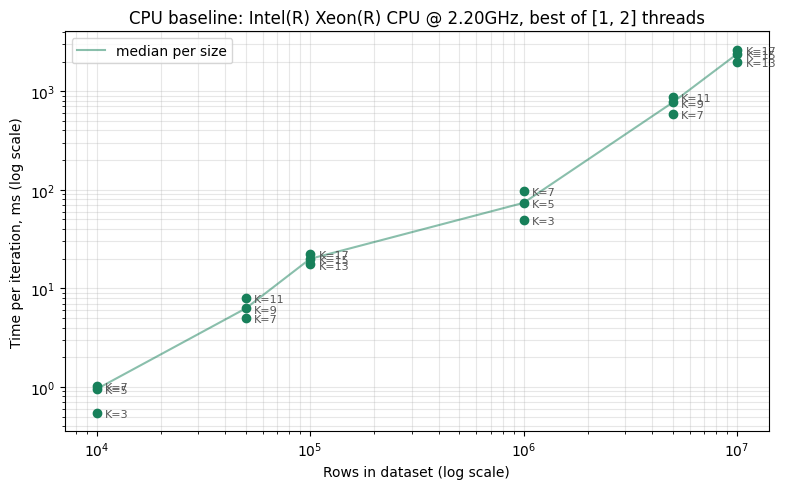

,file,rows,K,threads,per_iter_ms_median,per_iter_ms_by_threads,bench_iters,conv_iterations,conv_converged,conv_total_s,empty_clusters,smallest_cluster,largest_cluster
0,synthetic_data_10000_rows_10_cols_3_clusters,10000,3,1,0.5440,1:0.5440; 2:0.7131,822,2,True,0.0016,0,3255,3407
1,synthetic_data_10000_rows_10_cols_5_clusters,10000,5,1,0.9494,1:0.9494; 2:2.0982,396,2,True,0.0216,0,1952,2081
2,synthetic_data_10000_rows_10_cols_7_clusters,10000,7,1,1.0288,1:1.0288; 2:1.1944,482,2,True,0.0021,0,1368,1490
3,synthetic_data_50000_rows_10_cols_7_clusters,50000,7,1,5.0544,1:5.0544; 2:5.5196,88,2,True,0.0200,0,7077,7202
4,synthetic_data_50000_rows_10_cols_9_clusters,50000,9,1,6.2621,1:6.2621; 2:6.7356,85,2,True,0.0149,0,5472,5628
5,synthetic_data_50000_rows_10_cols_11_clusters,50000,11,2,8.0687,1:12.4644; 2:8.0687,66,2,True,0.0160,0,4434,4663
6,synthetic_data_100000_rows_10_cols_13_clusters,100000,13,1,17.5027,1:17.5027; 2:18.0708,20,2,True,0.0326,0,7480,7860
7,synthetic_data_100000_rows_10_cols_15_clusters,100000,15,2,19.9073,1:37.5312; 2:19.9073,21,2,True,0.0404,0,6438,6836
8,synthetic_data_100000_rows_10_cols_17_clusters,100000,17,1,22.3934,1:22.3934; 2:39.6172,24,2,True,0.0456,0,5748,5979
9,synthetic_data_1000000_rows_10_cols_3_clusters,1000000,3,1,48.9724,1:48.9724; 2:57.5508,20,2,True,0.2290,0,332651,333683


In [ ]:
import matplotlib.pyplot as plt

s = summary.sort_values(["rows", "K"])
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(s["rows"], s["per_iter_ms_median"], color="#17805A", zorder=3)
for _, r in s.iterrows():
    ax.annotate(f"K={int(r['K'])}", (r["rows"], r["per_iter_ms_median"]), textcoords="offset points",
                xytext=(6, -3), fontsize=8, color="#555555")
med = s.groupby("rows")["per_iter_ms_median"].median()
ax.plot(med.index, med.values, color="#17805A", alpha=0.5, label="median per size")
if s["rows"].nunique() > 1:
    ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Rows in dataset (log scale)")
ax.set_ylabel("Time per iteration, ms (log scale)")
ax.set_title(f"CPU baseline: {ENV['cpu_model']}, best of {THREADS_TO_TRY} threads" if HAVE_NUMBA else f"CPU baseline: {ENV['cpu_model']}")
ax.grid(True, which="both", alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig(OUT_DIR / "cpu_baseline_time_per_iteration.png", dpi=150)
plt.show()

cols = ["file", "rows", "K", "threads", "per_iter_ms_median", "per_iter_ms_by_threads", "bench_iters",
        "conv_iterations", "conv_converged", "conv_total_s", "empty_clusters", "smallest_cluster", "largest_cluster"]
display(s[cols].round(4))

## 9. Package the results

In [ ]:
zip_path = OUT_DIR / "cpu_baseline_results.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for p in sorted(OUT_DIR.glob("*")):
        if p.is_file() and p.suffix in {".csv", ".json", ".png"}:
            z.write(p, p.name)
print("Saved", zip_path, f"({zip_path.stat().st_size / 1e6:.1f} MB)")
if SAVE_ASSIGNMENTS and IN_COLAB and ASSIGNMENTS_DIR.exists():   # copy after all timing is finished
    dest = OUT_DIR / "assignments"
    dest.mkdir(exist_ok=True)
    for p in sorted(ASSIGNMENTS_DIR.glob("*.csv")):
        shutil.copy2(p, dest / p.name)
    print("Assignments copied to", dest)
elif SAVE_ASSIGNMENTS:
    print("Assignments are in", ASSIGNMENTS_DIR)
if IN_COLAB:
    from google.colab import files
    files.download(str(zip_path))

Saved /content/drive/MyDrive/results_cpu_baseline/cpu_baseline_results.zip (0.1 MB)
Assignments copied to /content/drive/MyDrive/results_cpu_baseline/assignments


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 10. Running the GPU side against this baseline

The GPU run is compared with this CPU baseline file by file. To keep the comparison like for like:

* **Same inputs:** same files and the same 9 feature columns, K from the file name, float32 data, and the starting centroids from `OUT_DIR/initial_centroids_<file>.csv` (load them; do not re-run k-means++ on the GPU).
* **Same algorithm and stopping rule:** Lloyd's algorithm, `TOL = 1e-4`, `MAX_ITER = 1000`, largest centroid movement (L2) as the stopping test, empty clusters keep their position. Keep centroid sums in float64 (or check the results below).
* **Same timing protocol:** warm-up, then the median of 5 timed runs of a fixed iteration count, each lasting at least 0.5 s. Synchronise the device before reading the clock (`torch.cuda.synchronize()` or `cp.cuda.Device().synchronize()`), and time host-to-device transfer separately.
* **Speedup per file = CPU time per iteration ÷ GPU time per iteration**, from `per_iter_ms_median`. Report it with the CPU model from `environment.json`, the thread count from `summary.csv`, and the GPU model.
* **Results check:** from the same starting centroids, compare final centroids with `final_results_<file>.csv`, and per-ID clusters with `assignments/assignments_<file>.csv` (join on `ID`). Expect close to 100% agreement; differences are IDs almost equally close to two centroids. Iteration counts to convergence can differ slightly for the same reason, which is why time per iteration is the headline measure.